<a href="https://colab.research.google.com/github/aaronteork/CS5284_GML/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch-geometric

In [ ]:
# Imports
import sys
from google.colab import drive
from pathlib import Path
import torch
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go

In [ ]:
# Mount drive and folders
drive.mount('/content/drive', force_remount=True)

FOLDER_NAME = 'cs5284_project'
PROJECT_DIR = Path(f'/content/drive/MyDrive/{FOLDER_NAME}')
DATA_DIR = PROJECT_DIR / "data"
SCRIPT_DIR = PROJECT_DIR / "scripts"

LOCAL_DATA_DIR = Path('/content/data')
LOCAL_DATA_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(SCRIPT_DIR.resolve()))

Mounted at /content/drive


In [ ]:
# Read data
import utils

data = utils.read_data(DATA_DIR, LOCAL_DATA_DIR)

Found 2 zip file(s): ['DE.zip', 'MD.zip']
Extracting DE.zip to /content/data...
Finished extracting DE.zip!
Extracting MD.zip to /content/data...
Finished extracting MD.zip!


/usr/local/lib/python3.13/dist-packages/torch/_utils.py:358: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  result = torch.sparse_coo_tensor(


DE: Symmetric = False
MD: Symmetric = False


In [ ]:
# Verify some of the statistics in the paper's Table 1
# Found some discrepancies
# Accidents per month for DE: 2761 (data) vs 2763 (paper)
# Average road length for MD: 212 (data) vs 211 (paper)
# Traffic volume remains a huge discrepancy, especially for MD
# Crash rate is not calculated because we dont have the denominator (probably need to google but i dont think that will be a significant initiative for now)
# Did not check betweeness centrality to since it will be computationally expensive
#   Can load from the repo is we want to

for state, info in data.items():
    print(f"=========={state}==========")
    adj = info["adj"]
    edges = info["edges"]
    accidents = info["accidents"]

    # Graph statistics
    n_nodes = adj.shape[0]
    n_roads = adj.values().count_nonzero().item()

    source, target = adj.indices()
    degree = torch.bincount(source, minlength=n_nodes)

    # Accident statistics
    monthly_accidents = accidents.groupby(
        ["year", "month"]
    )["acc_count"].sum()

    # Road length
    lengths = edges["length"].coalesce()
    road_lengths = lengths.values()
    road_lengths = road_lengths[road_lengths > 0]

    # Directed Traffic volume
    observed = set()
    for year, traffic in info["edge_features_traffic"].items():
        aadt = traffic["AADT"].coalesce()
        valid = torch.isfinite(aadt.values())
        u, v = aadt.indices()[:, valid]
        observed.update(zip(u.tolist(), v.tolist()))
    directed_volume_pct = len(observed) / n_roads * 100

    # Undirected traffic volume
    # Traffic volume coverage (unique undirected roads)
    src, dst = adj.indices()
    roads = set(zip(
        torch.minimum(src, dst).tolist(),
        torch.maximum(src, dst).tolist()
    ))
    observed = set()
    for year, traffic in info["edge_features_traffic"].items():
        aadt = traffic["AADT"].coalesce()
        valid = torch.isfinite(aadt.values())
        u, v = aadt.indices()[:, valid]
        observed.update(zip(
            torch.minimum(u, v).tolist(),
            torch.maximum(u, v).tolist()
        ))
    undirected_volume_pct = len(observed & roads) / len(roads) * 100

    print(f"Start year: {accidents['year'].min()}")
    print(f"End year: {accidents['year'].max()}")
    print(f"Nodes: {n_nodes:,}")
    print(f"Roads: {n_roads:,}")
    print(f"Accidents/month: {monthly_accidents.mean():.0f}")
    print(f"Average degree: {degree.float().mean().item():.1f}")
    print(f"Maximum degree: {degree.max().item()}")
    print(f"Average road length (m): {road_lengths.float().mean().item():.0f}")
    print(f"Directed traffic volume: {directed_volume_pct:.2f}%")
    print(f"Undirected traffic volume: {undirected_volume_pct:.2f}%")


==========DE==========
Start year: 2009
End year: 2022
Nodes: 49,023
Roads: 116,196
Accidents/month: 2761
Average degree: 2.4
Maximum degree: 6
Average road length (m): 213
Directed traffic volume: 1.77%
Undirected traffic volume: 3.16%
==========MD==========
Start year: 2015
End year: 2022
Nodes: 250,565
Roads: 580,526
Accidents/month: 9149
Average degree: 2.3
Maximum degree: 8
Average road length (m): 212
Directed traffic volume: 0.76%
Undirected traffic volume: 1.40%


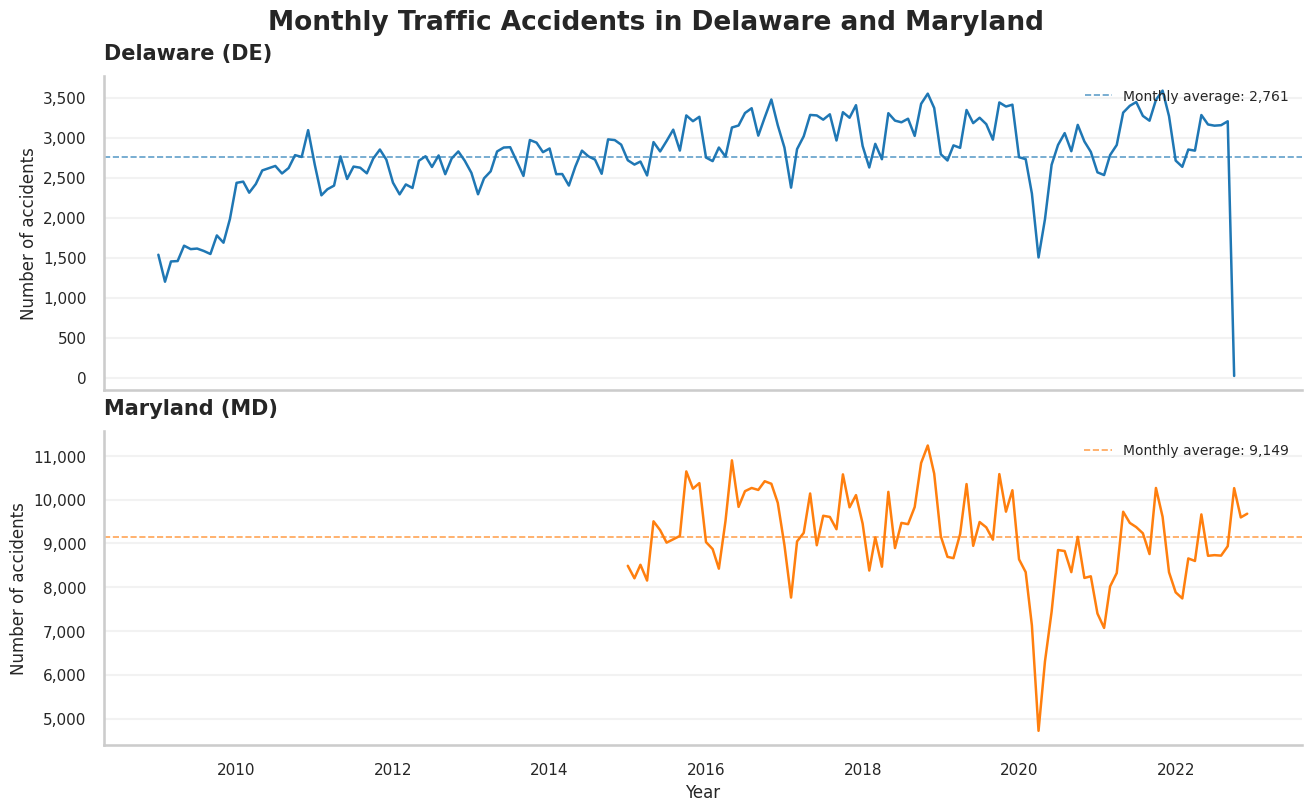

In [ ]:
# Accidents over time
# Need to check with Delware was increasing at the start and probably need to clean the zero at the end

sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True,
    layout="constrained"
)

colors = {"DE": "tab:blue", "MD": "tab:orange"}
names = {"DE": "Delaware", "MD": "Maryland"}

for ax, (state, info) in zip(axes, data.items()):
    monthly = (
        info["accidents"]
        .groupby(["year", "month"], as_index=False)["acc_count"]
        .sum()
    )

    monthly["date"] = pd.to_datetime(
        monthly[["year", "month"]].assign(day=1)
    )

    sns.lineplot(
        data=monthly,
        x="date",
        y="acc_count",
        ax=ax,
        color=colors[state],
        linewidth=1.8
    )

    # Average monthly accidents
    mean = monthly["acc_count"].mean()
    ax.axhline(
        mean,
        color=colors[state],
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label=f"Monthly average: {mean:,.0f}"
    )

    ax.set_title(
        f"{names[state]} ({state})",
        fontsize=15,
        fontweight="bold",
        loc="left",
        pad=12
    )

    ax.set_ylabel("Number of accidents", fontsize=12)
    ax.legend(frameon=False, fontsize=10, loc="upper right")

    ax.yaxis.set_major_formatter(
        mticker.StrMethodFormatter("{x:,.0f}")
    )

    ax.grid(axis="y", alpha=0.25)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="both", labelsize=11)

    sns.despine(ax=ax)

# Date axis
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlabel("Year", fontsize=12)

# Main title
fig.suptitle(
    "Monthly Traffic Accidents in Delaware and Maryland",
    fontsize=19,
    fontweight="bold"
)

plt.show()

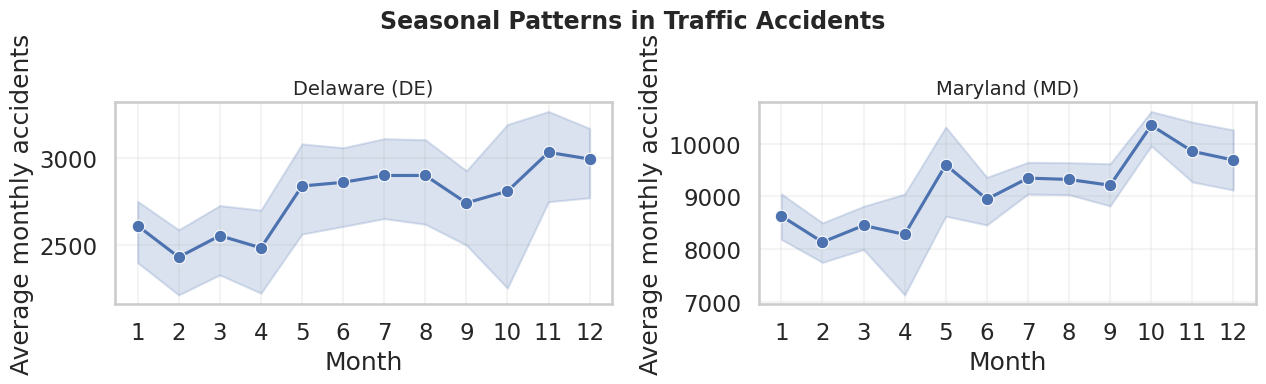

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (state, info) in zip(axes, data.items()):
    monthly = (
        info["accidents"]
        .groupby(["year", "month"], as_index=False)["acc_count"]
        .sum()
    )

    sns.lineplot(
        data=monthly,
        x="month",
        y="acc_count",
        marker="o",
        errorbar=("ci", 95),
        ax=ax
    )

    ax.set_title(f"{names[state]} ({state})", fontsize=14)
    ax.set_xlabel("Month")
    ax.set_ylabel("Average monthly accidents")
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.2)

fig.suptitle(
    "Seasonal Patterns in Traffic Accidents",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


DE
Roads with accidents: 36,466
Roads without accidents: 79,730
Zero-accident percentage: 68.62%
Maximum accidents on one road: 1,692

MD
Roads with accidents: 131,772
Roads without accidents: 448,754
Zero-accident percentage: 77.30%
Maximum accidents on one road: 992


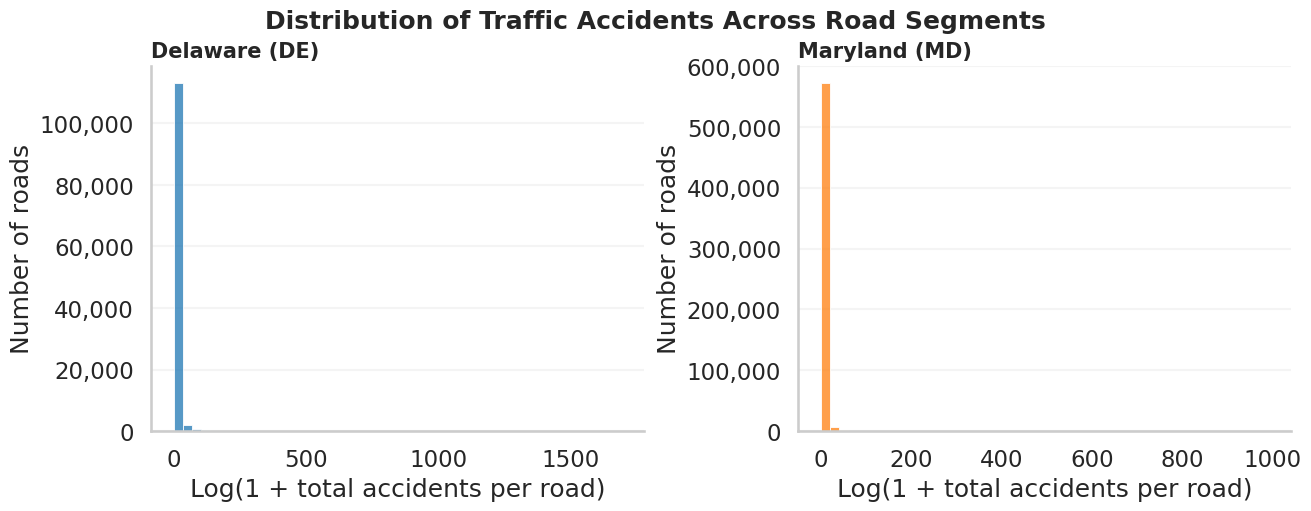

In [ ]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 5),
    layout="constrained"
)

for ax, (state, info) in zip(axes, data.items()):
    accidents = info["accidents"]
    adj = info["adj"].coalesce()

    # Aggregate accidents across the entire observation period
    road_accidents = (
        accidents.groupby(["node_1_idx", "node_2_idx"])["acc_count"]
        .sum()
    )

    # Include roads with zero recorded accidents
    n_roads = adj._nnz()
    n_zero = n_roads - len(road_accidents)

    counts = np.concatenate([
        road_accidents.to_numpy(),
        np.zeros(n_zero)
    ])

    sns.histplot(
        np.log1p(counts),
        bins=50,
        color=colors[state],
        ax=ax
    )

    ax.set_title(
        f"{names[state]} ({state})",
        fontsize=15,
        fontweight="bold",
        loc="left"
    )
    ax.set_xlabel("Log(1 + total accidents per road)")
    ax.set_ylabel("Number of roads")
    ax.yaxis.set_major_formatter(
        mticker.StrMethodFormatter("{x:,.0f}")
    )
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)

    sns.despine(ax=ax)

    print(f"\n{state}")
    print(f"Roads with accidents: {len(road_accidents):,}")
    print(f"Roads without accidents: {n_zero:,}")
    print(f"Zero-accident percentage: {n_zero / n_roads * 100:.2f}%")
    print(f"Maximum accidents on one road: {counts.max():,.0f}")

fig.suptitle(
    "Distribution of Traffic Accidents Across Road Segments",
    fontsize=18,
    fontweight="bold"
)

plt.show()

In [ ]:
for state, info in data.items():
    accidents = info["accidents"]
    n_roads = info["adj"].coalesce()._nnz()

    monthly = (
        accidents.groupby(["year", "month"])
        .agg(
            roads_with_accidents=(
                "acc_count",
                "size"
            ),
            total_accidents=(
                "acc_count",
                "sum"
            )
        )
    )

    monthly["zero_pct"] = (
        1 - monthly["roads_with_accidents"] / n_roads
    ) * 100

    print(f"\n{state}")
    print(
        f"Average zero-accident roads per month: "
        f"{monthly['zero_pct'].mean():.2f}%"
    )
    print(
        f"Minimum: {monthly['zero_pct'].min():.2f}%"
    )
    print(
        f"Maximum: {monthly['zero_pct'].max():.2f}%"
    )


DE
Average zero-accident roads per month: 98.06%
Minimum: 97.54%
Maximum: 99.98%

MD
Average zero-accident roads per month: 98.69%
Minimum: 98.45%
Maximum: 99.28%


In [ ]:
for state, info in data.items():
    accidents = info["accidents"].copy()

    accidents["date"] = pd.to_datetime(
        accidents[["year", "month"]].assign(day=1)
    )

    monthly_roads = {
        date: set(zip(group["node_1_idx"], group["node_2_idx"]))
        for date, group in accidents.groupby("date")
    }

    dates = sorted(monthly_roads)
    similarities = []

    for prev, curr in zip(dates[:-1], dates[1:]):
        # Only compare consecutive calendar months
        if curr != prev + pd.DateOffset(months=1):
            continue

        a = monthly_roads[prev]
        b = monthly_roads[curr]

        union = len(a | b)
        similarities.append(len(a & b) / union if union else np.nan)

    print(f"\n{state}")
    print(f"Average consecutive-month Jaccard: {np.nanmean(similarities):.4f}")


DE
Average consecutive-month Jaccard: 0.1298

MD
Average consecutive-month Jaccard: 0.1094


In [ ]:
for state, info in data.items():
    accidents = info["accidents"].copy()

    accidents["date"] = pd.to_datetime(
        accidents[["year", "month"]].assign(day=1)
    )

    monthly_roads = {
        date: set(zip(group["node_1_idx"], group["node_2_idx"]))
        for date, group in accidents.groupby("date")
    }

    dates = sorted(monthly_roads)
    n_roads = info["adj"].coalesce()._nnz()

    n_11 = n_10 = n_01 = n_00 = 0

    for prev, curr in zip(dates[:-1], dates[1:]):
        if curr != prev + pd.DateOffset(months=1):
            continue

        a = monthly_roads[prev]
        b = monthly_roads[curr]

        n_11 += len(a & b)
        n_10 += len(a - b)
        n_01 += len(b - a)
        n_00 += n_roads - len(a | b)

    p_repeat = n_11 / (n_11 + n_10)
    p_new = n_01 / (n_01 + n_00)

    print(f"\n{state}")
    print(f"P(accident next month | accident this month): {p_repeat:.2%}")
    print(f"P(accident next month | no accident this month): {p_new:.2%}")
    print(f"Relative risk: {p_repeat / p_new:.2f}x")


DE
P(accident next month | accident this month): 23.21%
P(accident next month | no accident this month): 1.52%
Relative risk: 15.22x

MD
P(accident next month | accident this month): 19.81%
P(accident next month | no accident this month): 1.06%
Relative risk: 18.63x


In [ ]:
state = "DE"
info = data[state]

nodes = pd.read_csv(
    info["filepath"] / "Nodes" / "node_features_2020_12.csv"
)

display(nodes[["node_id", "lat", "lon"]].head())

print("Number of nodes:", len(nodes))
print("Adjacency dimensions:", info["adj"].shape)
print("\nCoordinate ranges:")
print(nodes[["lat", "lon"]].agg(["min", "max"]))

,node_id,lat,lon
0,178623660,-75.486278,39.811026
1,178627690,-75.492470,39.811040
2,178630459,-75.493344,39.812246
3,178640679,-75.485697,39.810318
4,178640681,-75.484280,39.811013


Number of nodes: 49023
Adjacency dimensions: torch.Size([49023, 49023])

Coordinate ranges:
           lat        lon
min -75.788573  38.451243
max -75.049863  39.839218
